In [4]:
#%pip install mplsoccer==1.5.1

# Where Do Premier League Teams Over- and Underperform Their xG?
### A spatial analysis of 2025/26 using our neural network xG model

## From model comparison to team analysis

In the previous notebook we compared four xG models, a random forest, gradient boosting, logistic regression and a neural network, using the same training seasons (2021/22–2024/25) and the same test season (2025/26). The neural network came out best on both the Brier score (0.0783) and log loss (0.2771). Gradient boosting was very close (0.0785 and 0.2788), and the paired bootstrap could not separate the two. The random forest and logistic regression scored slightly worse.

All four models were also well calibrated, meaning their predicted probabilities match how often shots are actually scored. That matters for this notebook, because everything below adds up xG over groups of shots. Since the neural network scored best and its totals can be trusted, we use it for the rest of the analysis.

## Turning expected goals into a spatial question

An xG model gives the probability that a shot is scored, based on features such as where it was taken from and how it was taken. Adding up the xG of a team's shots gives the number of goals an average team would be expected to score from those chances. Comparing this with the goals the team actually scored shows whether it scored more or fewer than expected.

A season total, however, says nothing about where on the pitch the difference comes from. To find that out, we split the attacking end of the pitch into blocks and compare goals with xG in each one, for each of the 20 teams in 2025/26. We do this twice:

- **In attack**, using the shots each team took, to see where teams score more or fewer goals than their chances suggest.
- **In defence**, using the shots each team faced, to see where teams concede more or fewer goals than expected.

Finally, we look back at how well the model itself performs in different areas of the pitch, since any weakness in the model affects how these maps should be read.

## Loading packages and data

We use pandas and NumPy for the data, and mplsoccer to draw the pitches. mplsoccer must be version 1.5.1, because version 1.6.0 does not run on Python 3.9 (`pip install mplsoccer==1.5.1`).

We load three files:

- **The neural network's predictions** for every 2025/26 shot: its xG, whether the shot was a goal, and Understat's xG.
- **The cleaned shot data**, which holds each shot's location on the pitch.
- **The raw Understat data**, which holds the opponent for each shot. We need this for the defensive maps, which look at the shots each team faced.

The predictions are joined to the cleaned data using `row_id`, each shot's row number in the cleaned file. To check the join, we confirm that the outcome and Understat xG match for every shot. The opponent is then attached by matching each shot to the raw data on team, minute, home or away, score, xG and location.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# Neural network predictions for every 2025/26 shot
predictions = pd.read_csv("nn_xg_predictions_2025_26.csv")

# Cleaned shot data, which holds each shot's location (x, y)
shot_data = pd.read_csv("DST Understat shot data - cleaned.csv")

# Raw Understat data, which holds the opponent for each shot (needed for the defensive maps)
raw = pd.read_csv("understat_shots.csv")
raw = raw[raw["season"] == "2025/26"].copy()

# Attach each shot's details using row_id (0-based row number in the cleaned data)
match_cols = ["minute", "is_home", "team_goals_before", "opp_goals_before"]
shots = predictions.merge(shot_data[["x", "y", "result", "xg"] + match_cols],
                          left_on="row_id", right_index=True, validate="one_to_one")

# Check the two files line up: outcomes and Understat xG must match for every shot
assert (shots["goal"] == shots["result"]).all(), "goals do not match - row_ids do not line up"
assert np.allclose(shots["understat_xg"], shots["xg"]), "Understat xG does not match - row_ids do not line up"

# Attach the opponent by matching each shot to the raw data on team, minute, home/away, score,
# xG and location. The two files store decimals slightly differently, so we match on rounded values.
for df in (shots, raw):
    df["is_home"] = df["is_home"].astype(int)
    df["xg_r"], df["x_r"], df["y_r"] = df["xg"].round(4), df["x"].round(2), df["y"].round(2)

keys = ["team"] + match_cols + ["xg_r", "x_r", "y_r"]
shots = shots.merge(raw[keys + ["opponent"]].drop_duplicates(), on=keys, how="left", validate="many_to_one")
assert shots["opponent"].notna().all(), "some shots could not be matched to an opponent"
shots = shots.drop(columns=["result", "xg", "xg_r", "x_r", "y_r"] + match_cols)

assert len(shots) == 9483 and shots["team"].nunique() == 20
assert (shots["season"] == "2025/26").all()
print(len(shots), "shots,", shots["team"].nunique(), "teams")

9483 shots, 20 teams


## Building the heat maps

Our heat maps are inspired by the shot-location maps in the Soccermatics xG tutorial (https://soccermatics.readthedocs.io/en/latest/gallery/lesson2/plot_xGModelFit.html#plotting-shot-location). That tutorial uses mplsoccer to bin shot locations on a half pitch and colour each bin by the number of shots. We use the same approach, but split the pitch into fewer, larger blocks and colour each block by goals − xG for each team, so the maps show where a team's finishing differs from what the model expects.

Shot locations use Understat's coordinates scaled to a 120 × 80 pitch, with the attacking goal at x = 120. Each map shows the attacking end of the pitch with the goal at the top.

**Blocks.** We split the attacking end into 5 rows and 7 columns of equal size, giving 35 blocks per team. Each row is 8 units deep, running from x = 80 to the goal line. This depth was chosen so that the penalty spot sits at the centre of a block. The 7 columns divide the full width equally (about 11.4 units each). An odd number of columns means the centre of the pitch falls in the middle of a column, not on an edge. The few shots from further out than x = 80 (under 1%) are counted in the back row.

**Value in each block.** For each team and block we calculate

$$
\Delta = \sum_{i \,\in\, \text{block}} \left( y_i - p_i \right) = \text{goals} - \text{xG},
$$

where $p_i$ is the neural network's xG for shot $i$ and $y_i$ is 1 for a goal and 0 otherwise. A positive value means the team scored more than expected from that block (overperformance, green). A negative value means it scored fewer than expected (underperformance, red).

**Colours.** The colour runs smoothly from dark red through gold to dark green, capped at ±4 goals, so a block beyond that takes the darkest colour. The same scale is used for every team, so the maps can be compared directly. Blocks with fewer than 5 shots are greyed out, because a total from so few shots says very little. Each block is labelled with its goals (g) and total xG.

**Penalties** are included. The drawn penalty spot (x = 108, y = 40) sits at the centre of the middle block in the second row from goal. Understat records every penalty at x = 106.2, y = 40, slightly closer to the box than the drawn spot but still inside the same block, so all penalties fall in that one block.

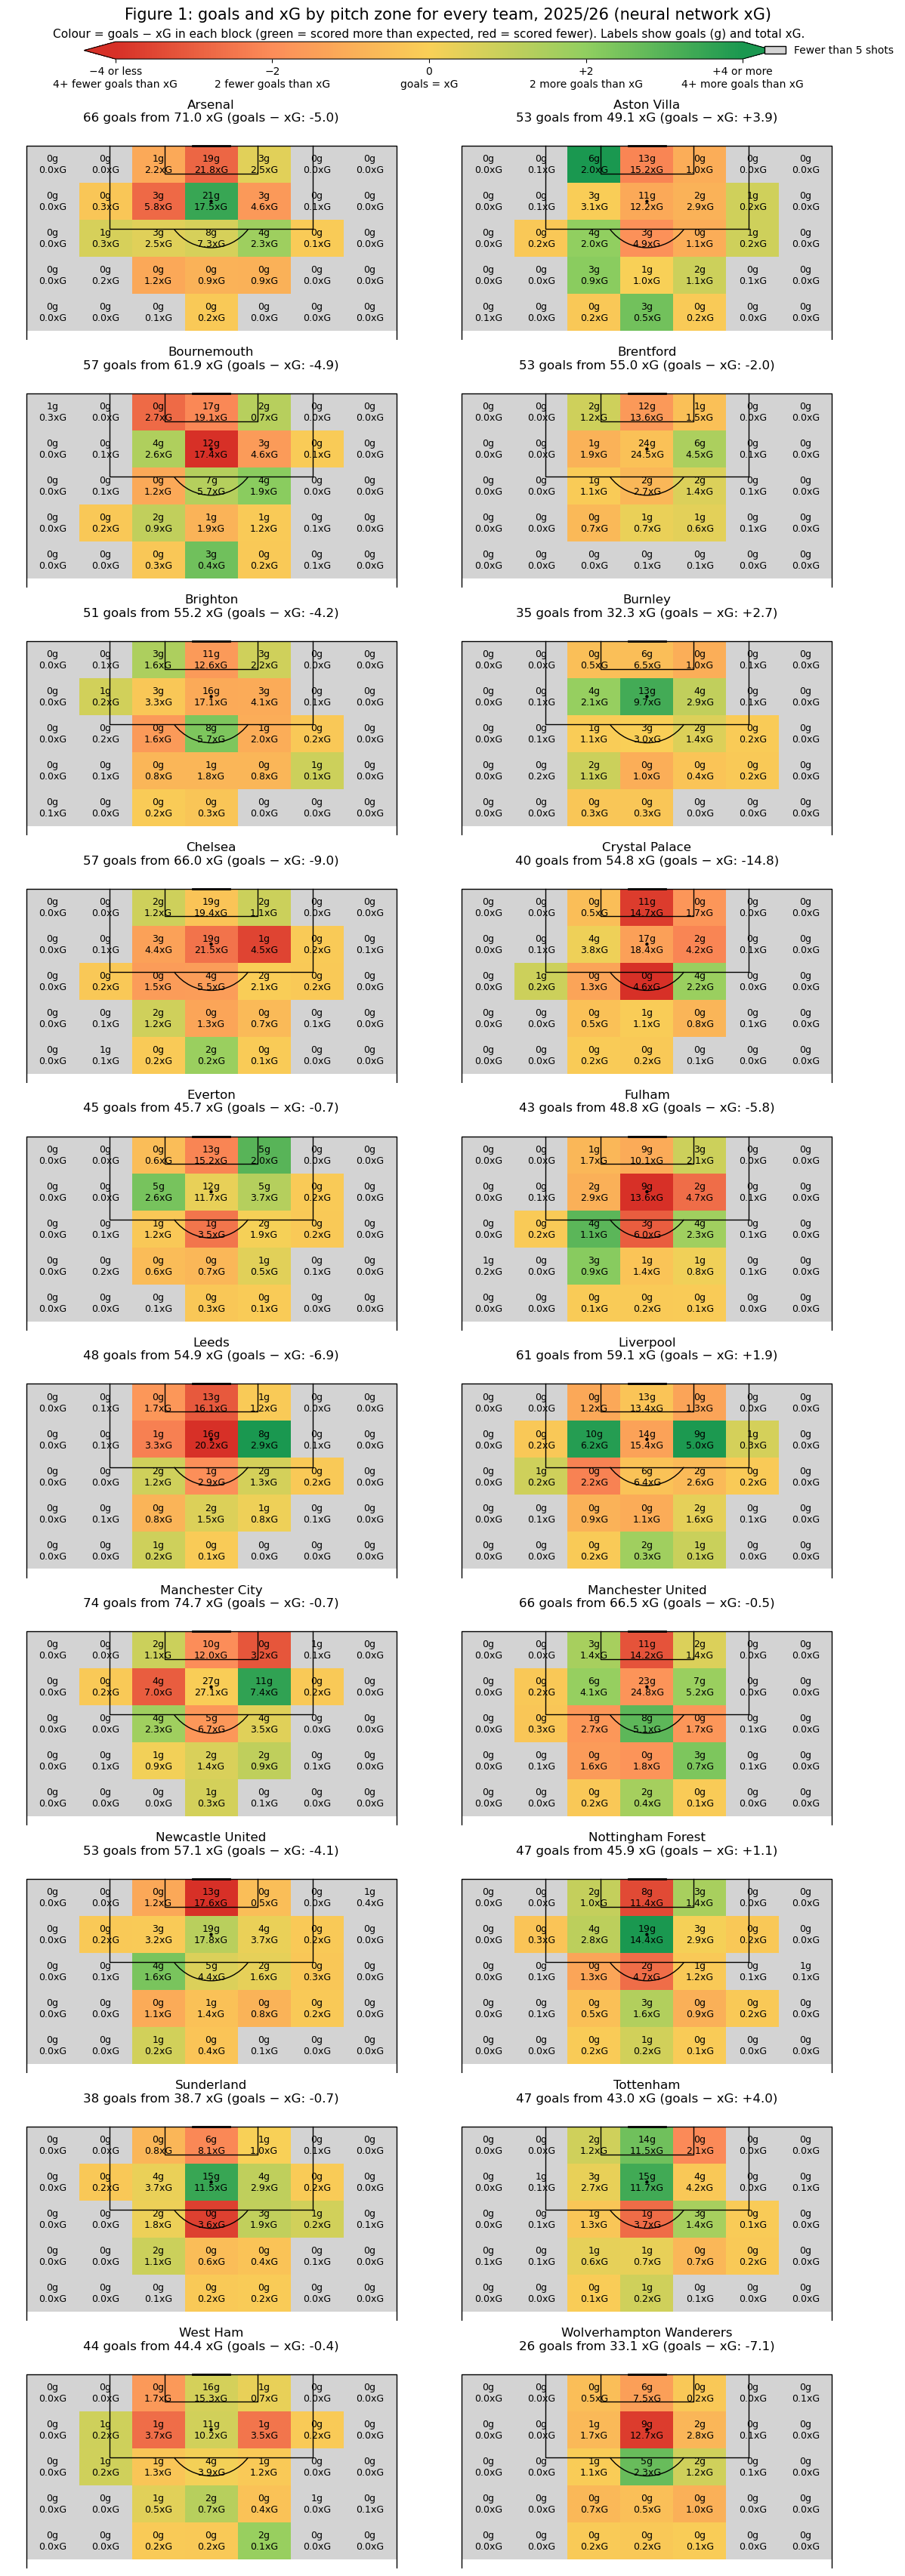

In [5]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch

# Blocks: 5 rows towards goal and 7 columns across the full width, all of equal size.
# Rows are 8 units deep, so the drawn penalty spot (x = 108) sits at the centre of a block, between its two labels.
# Understat records penalties at x = 106.2, which falls in the same block.
# An odd number of columns puts the penalty spot (y = 40) in the middle of the central column.
X_EDGES = list(range(80, 121, 8))         # 80, 88, 96, 104, 112, 120: five rows towards goal
Y_EDGES = list(np.linspace(0, 80, 8))     # 0, 11.4, ..., 80: seven columns across the pitch
MIN_SHOTS = 5                             # blocks with fewer shots are greyed out
LIMIT = 4                                 # colour scale runs from -4 to +4 goals

# Shots from further out than x = 80 are counted in the back row
shots["x_plot"] = shots["x"].clip(lower=X_EDGES[0])

pitch = VerticalPitch(pitch_type="statsbomb", half=True, pad_bottom=-18,
                      line_color="black", linewidth=1, line_zorder=2)

# Continuous gradient: dark red (fewer goals than xG) -> gold (goals = xG) -> dark green (more goals than xG)
cmap = LinearSegmentedColormap.from_list(
    "goals_minus_xg", ["#d73027", "#fc8d59", "#f9d057", "#91cf60", "#1a9850"])
cmap.set_bad("lightgrey")
norm = Normalize(vmin=-LIMIT, vmax=LIMIT)   # symmetric, so 0 sits exactly on gold

teams = sorted(shots["team"].unique())
fig, axs = plt.subplots(10, 2, figsize=(12, 34), layout="constrained")

for ax, team in zip(axs.flat, teams):
    t = shots[shots["team"] == team]
    bins = (X_EDGES, Y_EDGES)

    xg = pitch.bin_statistic(t["x_plot"], t["y"], values=t["nn_xg"], statistic="sum", bins=bins)
    goals = pitch.bin_statistic(t["x_plot"], t["y"], values=t["goal"], statistic="sum", bins=bins)
    count = pitch.bin_statistic(t["x_plot"], t["y"], statistic="count", bins=bins)

    # Colour: goals - xG in each block, greyed out where there are too few shots
    diff = xg.copy()
    diff["statistic"] = np.where(count["statistic"] >= MIN_SHOTS,
                                 goals["statistic"] - xg["statistic"], np.nan)

    pitch.draw(ax=ax)
    pitch.heatmap(diff, ax=ax, cmap=cmap, norm=norm)

    # Label each block with its goals and total xG
    for i in range(diff["statistic"].shape[0]):
        for j in range(diff["statistic"].shape[1]):
            g = int(np.nan_to_num(goals["statistic"][i, j]))
            x = np.nan_to_num(xg["statistic"][i, j])
            pitch.annotate(f"{g}g\n{x:.1f}xG", xy=(diff["cx"][i, j], diff["cy"][i, j]),
                           ax=ax, ha="center", va="center", fontsize=9, zorder=3)

    total = t["goal"].sum() - t["nn_xg"].sum()
    ax.set_title(f"{team}\n{int(t['goal'].sum())} goals from {t['nn_xg'].sum():.1f} xG "
                 f"(goals − xG: {total:+.1f})", fontsize=12)

# Key at the top, so it is seen before scrolling through the teams
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axs, location="top", fraction=0.012, aspect=40, extend="both",
                    shrink=0.8, pad=0.004)
cbar.set_ticks([-4, -2, 0, 2, 4])
cbar.set_ticklabels(["−4 or less\n4+ fewer goals than xG", "−2\n2 fewer goals than xG",
                     "0\ngoals = xG",
                     "+2\n2 more goals than xG", "+4 or more\n4+ more goals than xG"])
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.set_label("Colour = goals − xG in each block (green = scored more than expected, "
               "red = scored fewer). Labels show goals (g) and total xG.", fontsize=11)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.legend(handles=[Patch(facecolor="lightgrey", edgecolor="black", label="Fewer than 5 shots")],
               loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=False)

fig.suptitle("Figure 1: goals and xG by pitch zone for every team, 2025/26 (neural network xG)",
             fontsize=15)
fig.savefig("xg_heatmap_all_teams.png", dpi=200, bbox_inches="tight")   # full-size copy for the report
plt.show()

## What the attacking maps show

**Penalties barely change the picture.** Teams took 4.6 penalties each on average, and each one is worth about 0.82 xG in our model. A team that wins a lot of penalties therefore builds up more xG: Brentford took the most in the league (10, scoring 8), worth about 8 xG, compared with about 4 for an average team. But penalties add to goals and xG together, so they hardly move goals − xG. The largest effect was Crystal Palace, whose 8 from 8 added 1.6 to their total. Arsenal, for example, took only 4 penalties, so their strong green penalty-spot block (21 goals from 17.5 xG) comes mostly from open play: 17 non-penalty goals from 14.2 xG.

**The block closest to goal.** The central block nearest the goal is red for 19 of the 20 teams. Across the league it produced 240 goals from 275.3 xG, about 35 fewer goals than expected. When almost every team falls short in the same place, the cause is more likely to be the model than the teams, so we return to this block in the evaluation section. For now, it is more useful to compare teams with each other here than with zero. Tottenham (+2.5) and West Ham (+0.7) were the only teams to score more than expected, while Newcastle (−4.6) and Crystal Palace (−3.7) fell furthest short.

**Where teams convert well and where they don't.** The penalty-spot block is the busiest area on the pitch and shows the biggest differences. Nottingham Forest (+4.7, mostly open play) and Arsenal (+3.5) finished their chances there best. Bournemouth (−5.4) and Fulham (−4.6) wasted the most, and in both cases almost the whole shortfall comes from open play, not penalties.

**Crystal Palace.** Palace had the largest gap in the league, scoring 40 goals from 54.8 xG (−14.8). They were 4th after 15 games but finished 15th. Their problem was not a lack of shooting: they took 442 shots, slightly below the league average of 474, but their chances were good, with the 5th-highest xG per shot (0.124 against 0.111). Their conversion rate was the 18th-best in the league. On the maps the shortfall is spread across the central blocks. They scored nothing from 49 central shots around the edge of the box (4.6 xG) and were 3.7 goals short in the block closest to goal. Their perfect penalty record hides some of this: without penalties they were 16.4 goals below expected.

**One side of the pitch.** Some teams score very differently on the two sides of the pitch. Comparing non-penalty shots from the three columns on each side, Aston Villa scored 16 goals from 8.7 xG on the left of the map (+7.3) but only 6 from 6.8 xG on the right. Leeds show the reverse: 4 goals from 7.5 xG on the left and 12 from 6.5 xG on the right. Differences like these could reflect individual players, for example a strong finisher who cuts in from one wing, but our data does not record who took each shot.

**Teams close to expectation.** Manchester City (−0.7) and Manchester United (−0.5) finished very close to their xG over the season. City's busiest block, the penalty-spot block with 130 shots, was within 0.1 goals of expectation.

**What the maps cannot show.** Goals are rare: the whole season has 1,004, spread over 20 teams and 35 blocks each. Most blocks hold only a few shots (median 4), and 53% are greyed out. Shots from wide areas and the corners are especially rare, so the outer columns are grey for almost every team. A gap of one or two goals in a single block can easily be luck, so patterns that appear across several blocks, or across many teams, are more convincing than any one block.

## Defensive heat maps

The attacking maps looked at the shots each team took. Here we turn this around and look at the shots each team **faced**, to see where teams concede more or fewer goals than the chances against them suggest.

**Which shots.** Each shot is assigned to the defending team, which is the opponent of the team that took it. The blocks, the 5-shot minimum and the colour scale are the same as for the attacking maps, so the two figures can be compared directly.

**Value in each block.** For each team and block we calculate

$$
\Delta_{\text{def}} = \sum_{i \,\in\, \text{block}} \left( p_i - y_i \right) = \text{xG faced} - \text{goals conceded},
$$

where $p_i$ is the neural network's xG for shot $i$ and $y_i$ is 1 if it was a goal and 0 otherwise. Note that this is the **opposite way round** to the attacking maps:

- **Positive (green):** the team conceded fewer goals than expected from that block, so it defended better than expected.
- **Negative (red):** the team conceded more goals than expected, so it defended worse than expected.

This keeps green meaning "good for the team" in both figures. Each block is labelled with the goals conceded (g) and the total xG faced.

**Orientation.** The maps are rotated so the goal being defended is at the bottom. Because the pitch is turned through 180 degrees, left and right are also swapped compared with the attacking maps.

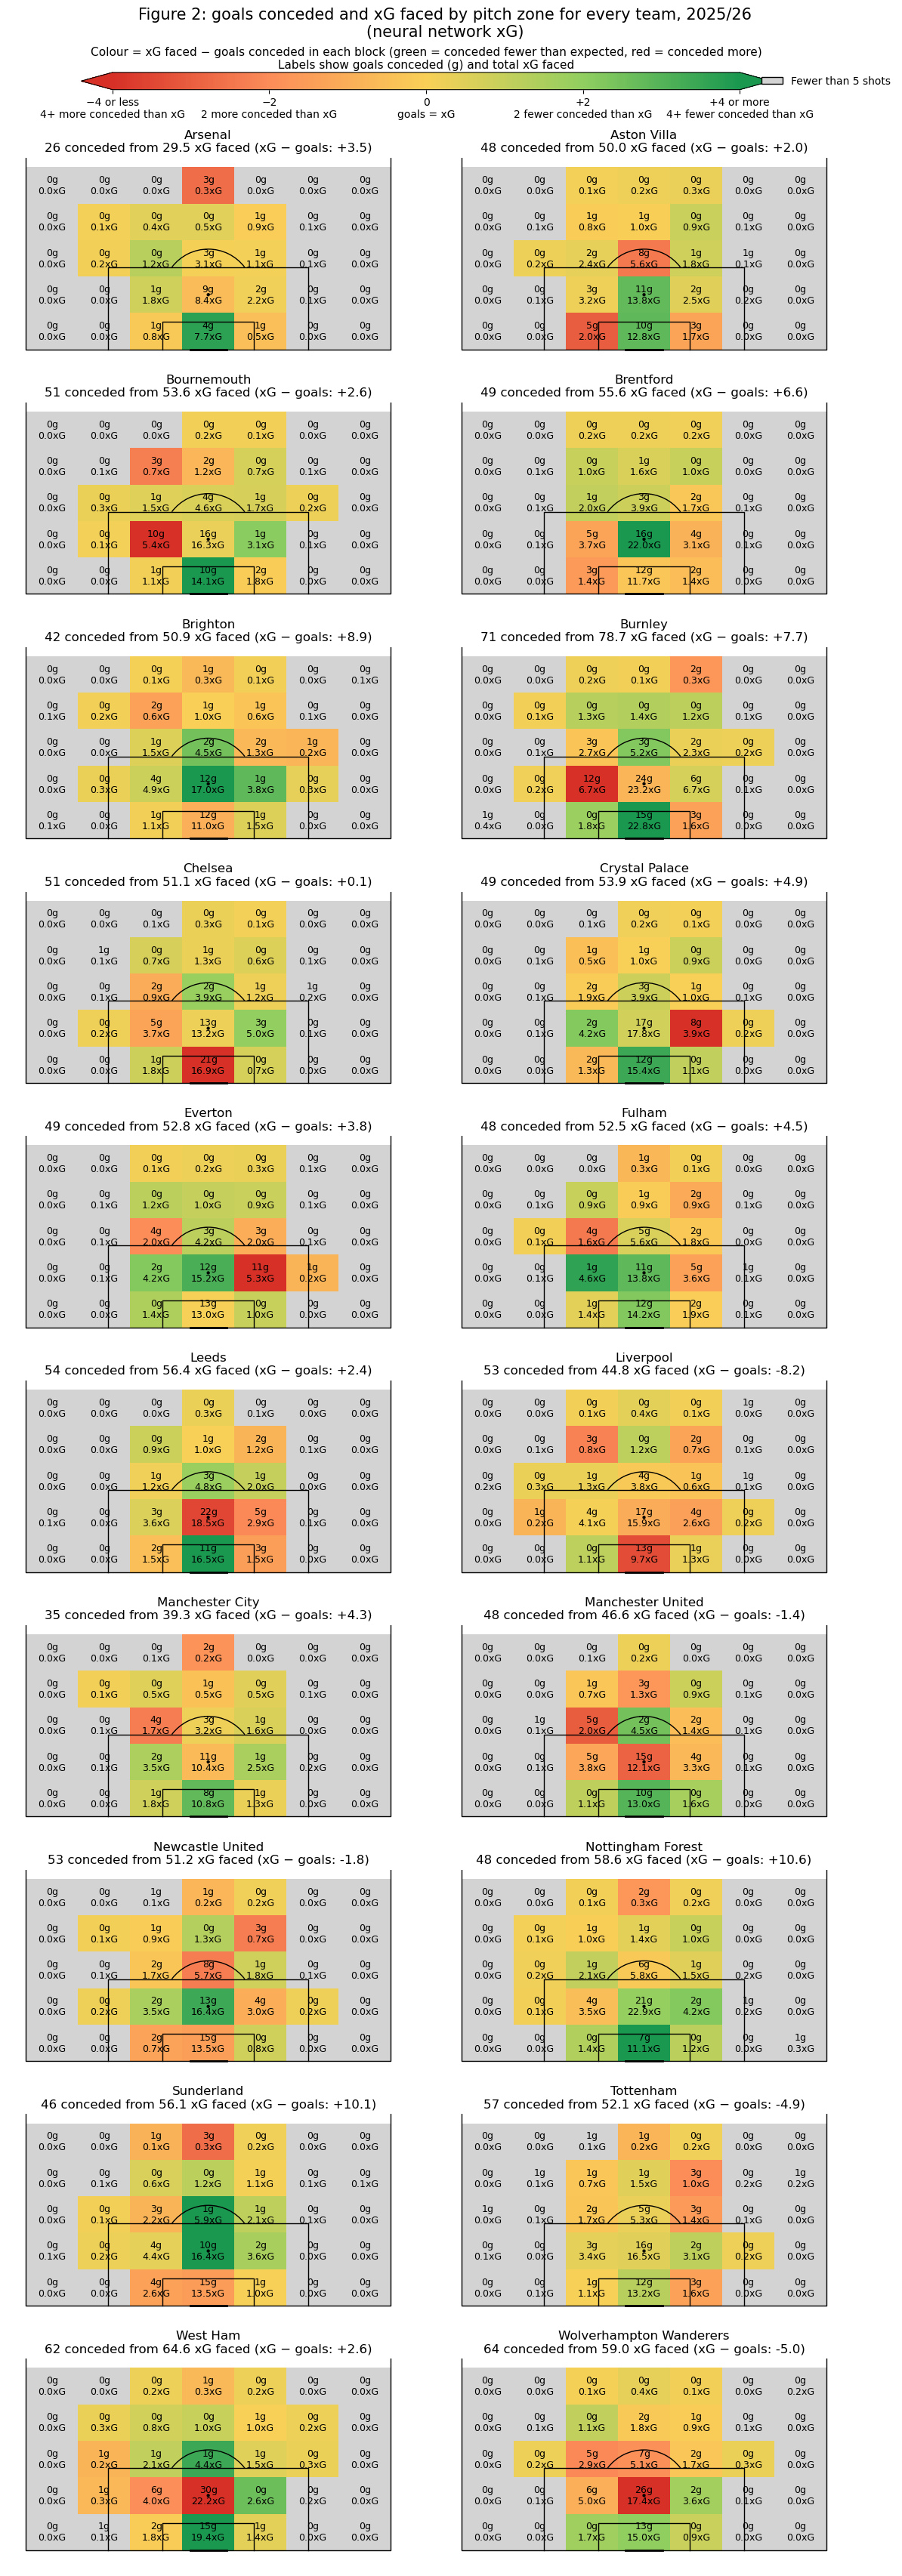

In [10]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch

# Same blocks as the attacking maps: 5 rows of 8 units towards goal and 7 equal columns across the pitch
X_EDGES = list(range(80, 121, 8))         # 80, 88, 96, 104, 112, 120: five rows towards goal
Y_EDGES = list(np.linspace(0, 80, 8))     # 0, 11.4, ..., 80: seven columns across the pitch
MIN_SHOTS = 5                             # blocks with fewer shots are greyed out
LIMIT = 4                                 # colour scale runs from -4 to +4 goals

# Shots from further out than x = 80 are counted in the back row
shots["x_plot"] = shots["x"].clip(lower=X_EDGES[0])

pitch = VerticalPitch(pitch_type="statsbomb", half=True, pad_bottom=-18,
                      line_color="black", linewidth=1, line_zorder=2)

# Continuous gradient: dark red (conceded more than xG) -> gold (goals = xG) -> dark green (conceded fewer than xG)
cmap = LinearSegmentedColormap.from_list(
    "xg_minus_goals_conceded", ["#d73027", "#fc8d59", "#f9d057", "#91cf60", "#1a9850"])
cmap.set_bad("lightgrey")
norm = Normalize(vmin=-LIMIT, vmax=LIMIT)   # symmetric, so 0 sits exactly on gold

# Each defending team is the opponent of the team that took the shot
teams = sorted(shots["opponent"].unique())
fig, axs = plt.subplots(10, 2, figsize=(12, 34), layout="constrained")

for ax, team in zip(axs.flat, teams):
    t = shots[shots["opponent"] == team]          # shots this team faced
    bins = (X_EDGES, Y_EDGES)

    xg = pitch.bin_statistic(t["x_plot"], t["y"], values=t["nn_xg"], statistic="sum", bins=bins)
    goals = pitch.bin_statistic(t["x_plot"], t["y"], values=t["goal"], statistic="sum", bins=bins)
    count = pitch.bin_statistic(t["x_plot"], t["y"], statistic="count", bins=bins)

    # Colour: xG faced - goals conceded in each block (positive = conceded fewer than expected),
    # greyed out where there are too few shots
    diff = xg.copy()
    diff["statistic"] = np.where(count["statistic"] >= MIN_SHOTS,
                                 xg["statistic"] - goals["statistic"], np.nan)

    pitch.draw(ax=ax)
    pitch.heatmap(diff, ax=ax, cmap=cmap, norm=norm)

    # Label each block with goals conceded and total xG faced
    for i in range(diff["statistic"].shape[0]):
        for j in range(diff["statistic"].shape[1]):
            g = int(np.nan_to_num(goals["statistic"][i, j]))
            x = np.nan_to_num(xg["statistic"][i, j])
            pitch.annotate(f"{g}g\n{x:.1f}xG", xy=(diff["cx"][i, j], diff["cy"][i, j]),
                           ax=ax, ha="center", va="center", fontsize=9, zorder=3)

    # Rotate the pitch 180 degrees so the goal being defended is at the bottom
    ax.invert_xaxis()
    ax.invert_yaxis()

    total = t["nn_xg"].sum() - t["goal"].sum()
    ax.set_title(f"{team}\n{int(t['goal'].sum())} conceded from {t['nn_xg'].sum():.1f} xG faced "
                 f"(xG − goals: {total:+.1f})", fontsize=12)

# Key at the top, so it is seen before scrolling through the teams
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axs, location="top", fraction=0.012, aspect=40, extend="both",
                    shrink=0.8, pad=0.004)
cbar.set_ticks([-4, -2, 0, 2, 4])
cbar.set_ticklabels(["−4 or less\n4+ more conceded than xG", "−2\n2 more conceded than xG",
                     "0\ngoals = xG",
                     "+2\n2 fewer conceded than xG", "+4 or more\n4+ fewer conceded than xG"])
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.set_label("Colour = xG faced − goals conceded in each block (green = conceded fewer than expected, red = conceded more)\n"
               "Labels show goals conceded (g) and total xG faced", fontsize=11)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.legend(handles=[Patch(facecolor="lightgrey", edgecolor="black", label="Fewer than 5 shots")],
               loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=False)

fig.suptitle("Figure 2: goals conceded and xG faced by pitch zone for every team, 2025/26\n(neural network xG)",
             fontsize=15)
fig.savefig("xg_heatmap_defence_all_teams.png", dpi=200, bbox_inches="tight")   # full-size copy for the report
plt.show()

## What the defensive maps show

**The maps lean green.** Across the league, the model expects about 53 more goals than were actually scored. In the attacking maps this showed up as red; in the defensive maps it shows up as green, so most teams appear to concede slightly fewer goals than expected. As with the attacking maps, it is more useful to compare teams with each other than with zero.

**The best defences stop chances being created.** Arsenal, the champions, had the best defence in the league, but not because they outperformed their xG by much (+3.5). They faced the fewest shots in the league (310), the lowest total xG (29.5) and the lowest xG per shot, and did not concede a single penalty. Most of their map is grey simply because opponents rarely got a shot away. Manchester City, who finished second, show the same pattern: the second-fewest shots faced (370) and 35 goals conceded, slightly fewer than expected (+4.3). For the strongest teams, good defending shows up in how few shots they face, not in the colour of the blocks.

**Teams that conceded far fewer than expected.** Nottingham Forest (+10.6), Sunderland (+10.1) and Brighton (+8.9) conceded the fewest goals relative to their chances. Sunderland stand out most: they faced 540 shots, the third-most in the league, yet conceded only 46 goals, the fourth-fewest. Their penalty-spot block (10 conceded from 16.5 xG) and the central block at the edge of the box (1 conceded from 5.9 xG) are both strongly green. This fits their season: they finished with 54 points, well above what their chances suggested.

**Burnley: overwhelmed, not unlucky.** Burnley faced the most shots (636), the most xG (78.7) and conceded the most goals (71), yet they actually conceded about 8 fewer than expected. In the block closest to goal they conceded 15 from 22.8 xG. Their problem was the sheer number of chances they allowed, not the finishing against them, and they were relegated.

**Teams that conceded more than expected.** Liverpool had the worst gap in the league, conceding 53 goals from 44.8 xG (−8.2). This is surprising, because they allowed relatively few chances: the fourth-fewest shots and fourth-lowest xG per shot. Their map is red close to goal, where they conceded 13 from 9.7 xG in the nearest block. Chelsea are similar near goal, conceding 21 from 16.9 xG there, one of very few red blocks in that position. Relegated Wolves (−5.0) and West Ham conceded far more than expected in the penalty-spot block: 26 from 17.4 xG and 30 from 22.2 xG respectively. West Ham still finish slightly positive overall because they were green elsewhere, which shows how a season total can hide a clear weak spot.

**Penalties.** Burnley and Brentford conceded the most penalties (8 each), while Arsenal conceded none. As in attack, penalties add to xG and goals together, so they barely change xG − goals; their main effect is on the total xG a team faces.

**One side of the pitch.** Some defences leak goals on one side much more than the other. Comparing non-penalty shots from the three columns on each side, Bournemouth conceded 15 goals from 9.3 xG on the left of their map but only 4 from 8.0 xG on the right. Everton show the reverse, conceding 15 from 9.9 xG on the right and 6 from 9.3 xG on the left. This could point to a weaker defender or goalkeeper positioning on one side, but our data cannot show why.

**What the maps cannot show.** Our data has no information about the goalkeeper or the positions of defenders, so a green block could reflect good goalkeeping, good blocking, or luck. The same limits as the attacking maps also apply: most blocks contain only a few shots, wide areas are almost always grey, and a gap of one or two goals in a single block can easily happen by chance.

## How reliable are the maps? Evaluating the model

**The model overrates chances close to goal.** Across the 2025/26 season the neural network expected 1,057.3 goals, while 1,004 were actually scored, so its total is about 5% too high. Most of this comes from one place: the central block closest to goal accounts for about 35 of the 53-goal difference, roughly two-thirds. A likely reason is that our data has no freeze-frame information, meaning the positions of the goalkeeper and defenders at the moment of the shot. A shot from close range looks like an excellent chance on location alone, but in practice the goalkeeper is often well placed or a defender is in the way. Without this information, the model cannot tell an open goal from a crowded six-yard box, so it rates close-range shots too highly on average.

**The test season was also lower-scoring than usual.** In the training seasons (2021/22–2024/25), 10.97% of shots were scored. In 2025/26 the figure was 10.59%. Had the test season matched the training rate, about 1,040 goals would have been scored instead of 1,004. Part of the overprediction is therefore the season itself, which no model trained on earlier seasons could have anticipated.

**Calibrated overall, but not everywhere.** In the model comparison, the neural network was well calibrated: across all shots, its predicted probabilities matched how often shots were scored. The maps show that this does not guarantee accuracy in every area of the pitch. The model can be right on average while being too high close to goal and slightly too low elsewhere. For example, central shots from long range produced 15 goals from 5.2 xG across the league, although this is a small number of shots. This kind of bias is only visible when the predictions are broken down by location, which is one of the things the spatial analysis adds.

**Not many goals to work with.** A season has around 1,000 goals, which is a small number once it is split across 20 teams and 35 blocks. Most blocks contain only a few shots, so a difference of one or two goals in a single block can easily be luck. We still chose to use one full season as the test set. It gives enough shots to test the model fairly, it lets us analyse each team's performance over a complete season, and since teams are promoted and relegated every year, a single season is the natural unit for comparing the teams in the league.

**Why the comparison is still fair.** The model never sees which team took a shot. Its xG depends only on the shot itself and the match situation, so every team is measured against the same standard. This is what makes goals − xG meaningful: when a team scores or concedes more or less than expected, the difference comes from what happened on the pitch, not from the model treating teams differently. Even with the bias near goal, the model affects all teams in the same way, so comparing teams with each other remains valid.

**Choice of model.** We used the neural network because it had the best Brier score and log loss over all shots. However, gradient boosting could not be separated from it statistically, and the models were chosen on overall accuracy, not on accuracy in each area of the pitch. The maps could look slightly different with another of our models, although the main patterns should be similar.

## Conclusion

Using our best xG model, we have shown where on the pitch each Premier League team scored and conceded more or fewer goals than their chances suggested in 2025/26. The maps highlight clear differences between teams, such as Crystal Palace's poor finishing across the central blocks, Sunderland's ability to concede far fewer goals than expected, and Arsenal's success in limiting the chances opponents created. They also reveal a weakness in the model itself, which overrates chances close to goal, most likely because it has no information on the goalkeeper and defenders. With more seasons of data and freeze-frame information, both the model and the maps could be made more reliable.